# Market making on Bitcoin
Every second we post a bid and an ask on BTCUSDT. A quote is **filled** if, in the next second, an aggressive trader trades strictly through it.
Data: free trade-by-trade files from Binance (`data.binance.vision`), no API key needed.




### The pipeline code


In [ ]:
%%writefile mm_pipeline.py
"""
Market-making quoting pipeline on Bitcoin trades (Binance BTCUSDT).

Every second we post a bid and an ask. A quote is filled if, in the NEXT second,
an aggressive trader trades strictly through it:
    - an aggressive SELL below our bid  -> we buy at our bid
    - an aggressive BUY  above our ask  -> we sell at our ask

Steps
1. clean the trades and put them on a 1-second grid
2. liquidity score L (this minute ranked against the last 24 hours)
3. staleness check
4. half-spread h
5. impact
6. inventory limits + skew
"""
import numpy as np
import pandas as pd

# ---------------- settings (all spreads in bps = 0.01%) ----------------
H_MIN = 0.5        # smallest half-spread allowed
B = 0.5            # base half-spread
K1 = 1.0           # extra half-spread per bps of 1-second volatility
K2 = 2.0           # extra half-spread when liquidity is low
K_Q = 0.5          # impact per clip, when liquidity is low
CLIP_USD = 1000    # size of each trade in dollars
I_BASE = 10        # inventory limit in clips when L = 1
K_SKEW = 1.0       # how hard we shade quotes against our inventory
MAX_AGE = 5        # seconds without a trade before the price is "stale" (when L = 1)
FEE_BPS = 0.0      # fee paid per fill


# ---------------- load ----------------
def load_binance(raw):
    """Binance aggTrades file -> DataFrame with ts, price, qty, aggressive_sell."""
    raw = raw.iloc[:, :7].copy()
    raw.columns = ["id", "price", "qty", "first", "last", "time", "buyer_maker"]
    raw = raw[pd.to_numeric(raw["price"], errors="coerce").notna()]         # drop a header row if there is one
    unit = "us" if float(raw["time"].iloc[0]) > 1e14 else "ms"              # Binance switched to microseconds in 2025
    df = pd.DataFrame({
        "ts": pd.to_datetime(raw["time"].astype("int64"), unit=unit),
        "price": raw["price"].astype(float),
        "qty": raw["qty"].astype(float),
        "aggressive_sell": raw["buyer_maker"].astype(str).str.lower() == "true",  # buyer was resting -> seller hit the bid
    })
    return df


# ---------------- step 1: clean ----------------
def clean(df):
    df = df.sort_values("ts").drop_duplicates()                   # time order, no duplicate rows
    df = df[df["price"] > 0]                                      # no zero / negative prices
    recent = df["price"].rolling(100).median().shift(1)           # median of the previous 100 trades
    bad = (df["price"] / recent - 1).abs() > 0.01                 # more than 1% away = fat finger
    return df[~bad]


def to_seconds(df):
    """One row per second: last price (forward-filled), trade count, and aggressive flow."""
    t = df.set_index("ts")
    bars = pd.DataFrame({
        "price": t["price"].resample("1s").last(),
        "n_trades": t["price"].resample("1s").count(),
    })
    bars["sell_low"] = t.loc[t["aggressive_sell"], "price"].resample("1s").min()    # lowest aggressive sell
    bars["buy_high"] = t.loc[~t["aggressive_sell"], "price"].resample("1s").max()   # highest aggressive buy
    bars["last_trade"] = bars.index.to_series().where(bars["n_trades"] > 0).ffill()
    bars["price"] = bars["price"].ffill()                          # forward fill quiet seconds
    bars["age"] = (bars.index - bars["last_trade"]).dt.total_seconds()
    # fills are decided by what happens in the NEXT second
    bars["next_sell_low"] = bars["sell_low"].shift(-1)
    bars["next_buy_high"] = bars["buy_high"].shift(-1)
    return bars.dropna(subset=["price"])


# ---------------- step 2: liquidity score ----------------
def liquidity(bars):
    ret = np.log(bars["price"]).diff() * 1e4                      # 1-second returns in bps
    m = pd.DataFrame({
        "sigma": ret.resample("1min").std(),                      # volatility of this minute
        "n": bars["n_trades"].resample("1min").sum(),             # trades in this minute
    })
    sigma_rank = m["sigma"].rolling(1440, min_periods=60).rank(pct=True)   # 0..1 vs the last 24 hours
    n_rank = m["n"].rolling(1440, min_periods=60).rank(pct=True)
    s = 0.5 * (1 - sigma_rank) + 0.5 * n_rank
    m["L"] = 0.1 + 0.9 * s
    m = m.shift(1)                                                # only use the PREVIOUS minute
    return m.reindex(bars.index, method="ffill")                  # copy to every second


# ---------------- steps 3-6: quote and trade, second by second ----------------
def backtest(bars, liq, use_L=True, use_skew=True, flat_h=None):
    price = bars["price"].to_numpy()
    age = bars["age"].to_numpy()
    sell_low = bars["next_sell_low"].to_numpy()
    buy_high = bars["next_buy_high"].to_numpy()
    L_all = liq["L"].to_numpy() if use_L else np.where(liq["L"].notna(), 1.0, np.nan)
    sigma_all = liq["sigma"].to_numpy()

    inv, cash = 0.0, 0.0                                          # inventory in BTC, cash in USD
    equity, inventory, fills = [], [], []
    for t in range(len(price)):
        p, L, sigma = price[t], L_all[t], sigma_all[t]

        # step 3: staleness (also skip until the score exists)
        if np.isnan(L) or age[t] > MAX_AGE / L:
            equity.append(cash + inv * p); inventory.append(inv)
            continue

        # step 4: half-spread
        h = flat_h if flat_h is not None else max(H_MIN, B + K1 * sigma + K2 * (1 - L))
        # step 5: impact (we always trade 1 clip, so q / q_ref = 1)
        THETA = 0.0        # instrument offset theta_i (0 = no known bias)   ← new setting

        # step 5: impact offset (we always trade 1 clip, so q / q_ref = 1)
        offset = THETA + K_Q * (1 - L)

        ref = p * (1 - side * offset / 1e4)                   # price + offset for the ask, price - offset for the bid
        quote = ref * (1 + (skew - side * h * width) / 1e4)   # then -/+ h and the skew
        # step 6: inventory limit and skew
        clip = CLIP_USD / p                                       # 1 clip in BTC
        i_max = I_BASE * L * clip
        skew = -K_SKEW * inv / i_max if use_skew else 0.0

        for side in (+1, -1):                                     # +1 we buy at the bid, -1 we sell at the ask
            new_inv = inv + side * clip
            if abs(new_inv) <= abs(inv) or abs(new_inv) <= i_max:
                width = 1                                          # accept
            elif abs(new_inv) <= 1.5 * i_max:
                width = 2                                          # accept, but twice as wide
            else:
                continue                                           # reject: don't quote this side
            quote = p * (1 + (skew - side * (h * width + impact)) / 1e4)
            hit = sell_low[t] < quote if side == 1 else buy_high[t] > quote
            if hit:
                inv += side * clip
                cash -= side * clip * quote + CLIP_USD * FEE_BPS / 1e4
                fills.append((t, side, quote))

        equity.append(cash + inv * p); inventory.append(inv)

    return pd.DataFrame({"equity": equity, "inventory_btc": inventory}, index=bars.index), fills


# ---------------- results ----------------
def markouts(fills, bars, horizons=(1, 10, 60)):
    """Average profit of a fill k seconds later, in bps. Negative = we were picked off."""
    price = bars["price"].to_numpy()
    out = {}
    for k in horizons:
        vals = [side * (price[min(t + k, len(price) - 1)] - px) / px * 1e4 for t, side, px in fills]
        out[f"markout_{k}s_bps"] = np.mean(vals) if vals else np.nan
    return out


def summary(res, fills, bars):
    traded = len(fills) * CLIP_USD
    pnl = res["equity"].iloc[-1]
    return {
        "pnl_usd": pnl,
        "fills": len(fills),
        "pnl_bps_of_traded": pnl / traded * 1e4 if traded else np.nan,
        "max_inventory_usd": (res["inventory_btc"].abs() * bars["price"]).max(),
        **markouts(fills, bars),
    }


Overwriting mm_pipeline.py


### Download real BTC trades
`DAYS` = how many recent full days to use. 3 days ≈ a few million trades; the first hour is used to warm up the liquidity score.

In [ ]:
import io, zipfile, urllib.request, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import mm_pipeline as mm
os.makedirs("results", exist_ok=True)

SYMBOL, DAYS = "BTCUSDT", 3
dates = [(pd.Timestamp.utcnow().normalize() - pd.Timedelta(days=d)).strftime("%Y-%m-%d") for d in range(DAYS + 1, 1, -1)]

def download_day(symbol, day):
    url = f"https://data.binance.vision/data/spot/daily/aggTrades/{symbol}/{symbol}-aggTrades-{day}.zip"
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
    return pd.read_csv(z.open(z.namelist()[0]), header=None)

raw = pd.concat([download_day(SYMBOL, d) for d in dates])
trades = mm.load_binance(raw)
print(dates, f"{len(trades):,} trades")
trades.head()

['2026-11-09', '2026-11-10', '2026-11-11'] 2,639,052 trades


,ts,price,qty,aggressive_sell
0,2026-11-09 00:00:00.183637,74851.44,0.00130,False
1,2026-11-09 00:00:00.275404,74851.44,0.15836,False
2,2026-11-09 00:00:00.358036,74851.43,0.12337,True
3,2026-11-09 00:00:00.358036,74851.42,0.02735,True
4,2026-11-09 00:00:00.360218,74850.24,0.00016,True


### Step 1 — clean and put on a 1-second grid

In [ ]:
n0 = len(trades)
trades = mm.clean(trades)
print(f"removed {n0 - len(trades):,} bad / duplicate trades out of {n0:,}")
bars = mm.to_seconds(trades)
print(f"{len(bars):,} seconds, {(bars.n_trades == 0).mean():.1%} of them with no trade (forward-filled)")
bars.head()

removed 351 bad / duplicate trades out of 2,639,052
259,200 seconds, 15.0% of them with no trade (forward-filled)


,price,n_trades,sell_low,buy_high,last_trade,age,next_sell_low,next_buy_high
ts,,,,,,,,
2026-11-09 00:00:00,74839.61,27,74839.61,74851.44,2026-11-09 00:00:00,0.0,74839.61,74839.62
2026-11-09 00:00:01,74839.61,7,74839.61,74839.62,2026-11-09 00:00:01,0.0,74820.18,74839.62
2026-11-09 00:00:02,74825.80,64,74820.18,74839.62,2026-11-09 00:00:02,0.0,NaN,74832.24
2026-11-09 00:00:03,74832.24,50,NaN,74832.24,2026-11-09 00:00:03,0.0,74832.23,74861.76
2026-11-09 00:00:04,74861.76,86,74832.23,74861.76,2026-11-09 00:00:04,0.0,74861.75,74893.17


### Step 2 — liquidity score
Each minute's volatility and trade count are ranked against the last 24 hours. Busy and calm → L near 1; quiet and jumpy → L near 0.1.

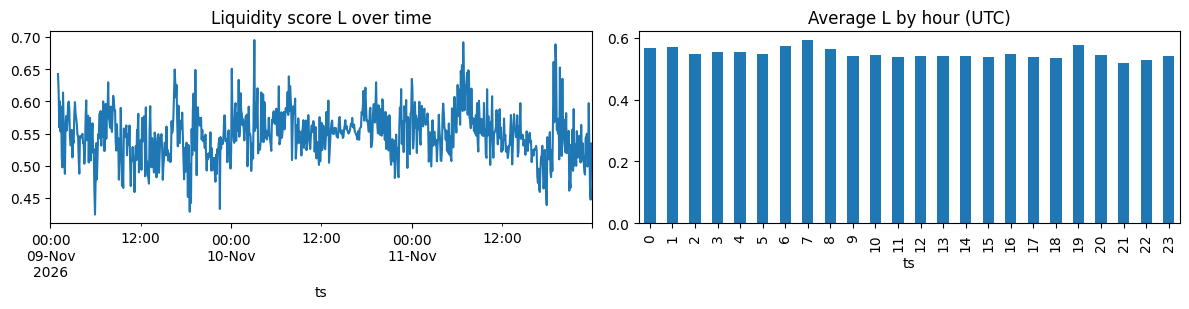

In [ ]:
liq = mm.liquidity(bars)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
liq["L"].resample("5min").mean().plot(ax=ax[0], title="Liquidity score L over time")
liq["L"].groupby(liq.index.hour).mean().plot.bar(ax=ax[1], title="Average L by hour (UTC)")
plt.tight_layout(); plt.savefig("results/liquidity.png", dpi=130); plt.show()

### Steps 3–6 — quote every second and trade

,0
pnl_usd,-413.95
fills,4067.00
pnl_bps_of_traded,-1.02
max_inventory_usd,6464.66
markout_1s_bps,-0.81
markout_10s_bps,-1.36
markout_60s_bps,-1.34


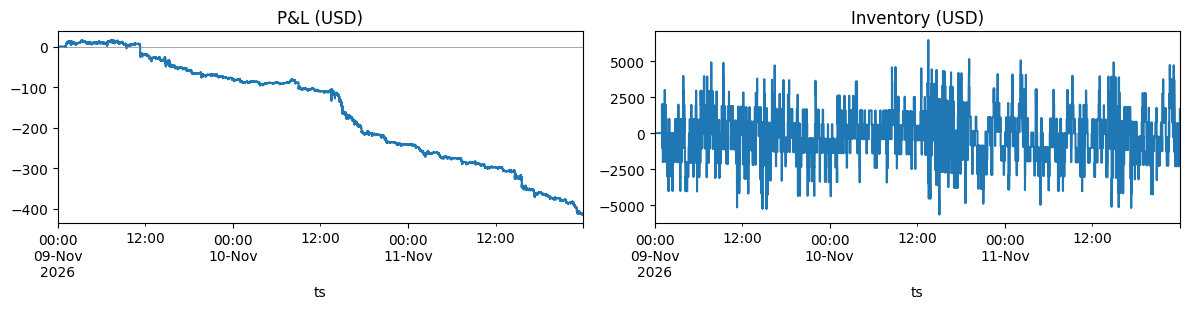

In [ ]:
res, fills = mm.backtest(bars, liq)
display(pd.Series(mm.summary(res, fills, bars)).round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
res["equity"].plot(ax=ax[0], title="P&L (USD)"); ax[0].axhline(0, c="grey", lw=.5)
(res["inventory_btc"] * bars["price"]).plot(ax=ax[1], title="Inventory (USD)")
plt.tight_layout(); plt.savefig("results/pnl_inventory.png", dpi=130); plt.show()

### Does each step help?
Same data, one piece switched off at a time. Look at **markouts**: the average profit of a fill 1, 10 and 60 seconds later. Negative means we were picked off by informed traders.

In [ ]:
variants = {
    "Full pipeline": {},
    "No liquidity score (L = 1)": {"use_L": False},
    "No inventory skew": {"use_skew": False},
    "Flat 1 bp half-spread": {"flat_h": 1.0},
}
table = {}
for name, kw in variants.items():
    r, f = mm.backtest(bars, liq, **kw)
    table[name] = mm.summary(r, f, bars)
table = pd.DataFrame(table).T.round(2)
table.to_csv("results/comparison.csv")
table

,pnl_usd,fills,pnl_bps_of_traded,max_inventory_usd,markout_1s_bps,markout_10s_bps,markout_60s_bps
Full pipeline,-413.95,4067.0,-1.02,6464.66,-0.81,-1.36,-1.34
No liquidity score (L = 1),-2167.59,18723.0,-1.16,9987.24,-0.64,-1.19,-1.18
No inventory skew,-231.24,3309.0,-0.70,7524.00,-0.84,-1.35,-1.35
Flat 1 bp half-spread,-2665.03,21806.0,-1.22,7582.71,-0.71,-1.22,-1.22


### Fees
Binance's standard maker fee would wipe out most strategies; professional market makers pay much less or get rebates. Try it:

In [ ]:
mm.FEE_BPS = 1.0                 # try 0, 0.5, 1, 2
r, f = mm.backtest(bars, liq)
print(pd.Series(mm.summary(r, f, bars)).round(2))
mm.FEE_BPS = 0.0

pnl_usd              -820.65
fills                4067.00
pnl_bps_of_traded      -2.02
max_inventory_usd    6464.66
markout_1s_bps         -0.81
markout_10s_bps        -1.36
markout_60s_bps        -1.34
dtype: float64


Conclusion

On three days of real BTCUSDT trades, the pipeline kept inventory under control, but every version lost about 1 bp for every dollar traded. The full pipeline lost the least (−$414, against −$2,665 for a flat spread), mainly because it traded less.

The main problem is speed. Our strategy updates its quotes once per second, while Bitcoin trades many times per second. When the price moves, faster traders hit our old quotes before we can adjust them, so we buy just before the price falls and sell just before it rises. The negative markouts show exactly this: the price keeps moving against us after each fill. Real market makers use high-frequency infrastructure to update or cancel their quotes within microseconds of a price move, so they are rarely caught with stale prices. Running the same pipeline at that speed, close to the exchange, would remove most of this loss.

The second problem is the data. We only see trades, not the order book, so we can’t tell where our order would sit in the queue or whether it would really be filled, and we miss the small, uninformed trades that pay the spread. With full order-book data, the backtest could model queue position and fill probability properly, and the strategy could use order-book imbalance to anticipate price moves and adjust its quotes in time.

Finally, the liquidity score barely changed over time, because on a single asset volatility and trade count rise together and cancel out in the formula. Measuring liquidity as the price move per trade, or using order-book depth and spread, would give a score that really separates calm and stressed periods.